In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold

import tensorflow as tf
from tensorflow.keras import datasets, layers, models, losses, utils

import tensorflow.keras.backend as K

from keras.callbacks import EarlyStopping

In [ ]:
train_validation_images = []
test_images = []

train_validation_labels = []
test_labels = []

In [ ]:
for file in os.listdir('/content/drive/MyDrive/forest_fire/Testing/fire'):
  test_images.append(np.array(Image.open('/content/drive/MyDrive/forest_fire/Testing/fire/' + file)))
  test_labels.append(1)

for file in os.listdir('/content/drive/MyDrive/forest_fire/Testing/nofire'):
  test_images.append(np.array(Image.open('/content/drive/MyDrive/forest_fire/Testing/nofire/' + file)))
  test_labels.append(0)

for file in os.listdir('/content/drive/MyDrive/forest_fire/Training and Validation/fire'):
  train_validation_images.append(np.array(Image.open('/content/drive/MyDrive/forest_fire/Training and Validation/fire/' + file)))
  train_validation_labels.append(1)

for file in os.listdir('/content/drive/MyDrive/forest_fire/Training and Validation/nofire'):
  train_validation_images.append(np.array(Image.open('/content/drive/MyDrive/forest_fire/Training and Validation/nofire/' + file)))
  train_validation_labels.append(0)

In [ ]:
len(train_validation_images)+len(test_images)

1900

In [ ]:
train_images, validation_images, train_labels, validation_labels = train_test_split(train_validation_images, train_validation_labels, test_size = 0.2, random_state = 42)

In [ ]:
train_images = np.array(train_images)
validation_images = np.array(validation_images)
test_images = np.array(test_images)

train_labels = np.array(train_labels)
validation_labels = np.array(validation_labels)
test_labels = np.array(test_labels)

In [ ]:
train_labels = tf.keras.utils.to_categorical(train_labels, num_classes=2)
validation_labels = tf.keras.utils.to_categorical(validation_labels, num_classes=2)
test_labels = tf.keras.utils.to_categorical(test_labels, num_classes=2)

In [ ]:
num_epochs = 25

## LSTM

In [ ]:
# Configuration for K-Fold Cross-Validation
k_folds = 5
kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)

hidden_LSTM_layers = [1, 2, 3, 4, 5, 6]
activation_functions_LSTM = ['relu', 'sigmoid', 'tanh']
accuracies_LSTM = []

# Initialize variables to track the best model
best_accuracy = 0
best_model_config = None
best_model_path = None

for num_hidden_LSTM_layers in hidden_LSTM_layers:
    for activation_function in activation_functions_LSTM:
        fold_accuracies = []
        fold_precisions = []
        fold_recalls = []
        fold_f1_scores = []

        print(f"\nTraining with {num_hidden_LSTM_layers} hidden LSTM layers and '{activation_function}' activation...\n")

        for fold, (train_idx, val_idx) in enumerate(kf.split(range(len(train_images)))):
            print(f"\nTraining Fold {fold + 1}/{k_folds}...")

            # Prepare training and validation data for this fold
            train_data = tf.gather(train_images, train_idx)
            train_labels_fold = tf.gather(train_labels, train_idx)
            val_data = tf.gather(train_images, val_idx)
            val_labels_fold = tf.gather(train_labels, val_idx)

            # Build the model
            model = tf.keras.Sequential()

            # Reshape input for LSTM
            model.add(tf.keras.layers.Reshape((250, 250 * 3), input_shape=(250, 250, 3)))

            # First LSTM layer with return_sequences=True
            model.add(tf.keras.layers.LSTM(64, activation=activation_function, return_sequences=(num_hidden_LSTM_layers > 1)))

            # Add intermediate LSTM layers
            for i in range(num_hidden_LSTM_layers - 1):
                return_sequences = i < num_hidden_LSTM_layers - 2
                model.add(tf.keras.layers.LSTM(64, activation=activation_function, return_sequences=return_sequences))

            # Dense layers
            model.add(tf.keras.layers.Dense(64, activation=activation_function))
            model.add(tf.keras.layers.Dense(2, activation='softmax'))  # Output layer for 2 classes

            # Compile the model
            model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                          loss='categorical_crossentropy',
                          metrics=['accuracy'])

            # Train the model
            history = model.fit(train_data, train_labels_fold,
                                epochs=num_epochs,
                                validation_data=(val_data, val_labels_fold),
                                callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)])

            # Evaluate the model on validation data
            val_loss, val_accuracy = model.evaluate(val_data, val_labels_fold)
            fold_accuracies.append(val_accuracy)
            print(f"Fold {fold + 1} Accuracy: {val_accuracy:.4f}")

            # Calculate Precision, Recall, and F1-Score
            precision_metric = tf.keras.metrics.Precision()
            recall_metric = tf.keras.metrics.Recall()

            # Predict on validation data
            predictions = model.predict(val_data)
            predictions_classes = tf.argmax(predictions, axis=1)
            true_classes = tf.argmax(val_labels_fold, axis=1)

            # Update metrics
            precision_metric.update_state(true_classes, predictions_classes)
            recall_metric.update_state(true_classes, predictions_classes)

            precision = precision_metric.result().numpy()
            recall = recall_metric.result().numpy()
            f1_score = (2 * precision * recall) / (precision + recall + 1e-8)  # Avoid division by zero

            fold_precisions.append(precision)
            fold_recalls.append(recall)
            fold_f1_scores.append(f1_score)

            print(f"Fold {fold + 1} Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1_score:.4f}")

        # Calculate average metrics across folds for this configuration
        avg_fold_accuracy = tf.reduce_mean(fold_accuracies).numpy()
        std_dev_accuracy = tf.math.reduce_std(fold_accuracies).numpy()
        avg_precision = tf.reduce_mean(fold_precisions).numpy()
        avg_recall = tf.reduce_mean(fold_recalls).numpy()
        avg_f1_score = tf.reduce_mean(fold_f1_scores).numpy()

        print(f"\nConfiguration ({num_hidden_LSTM_layers} hidden layers, '{activation_function}' activation):")
        print(f"Average Fold Accuracy: {avg_fold_accuracy:.4f}")
        print(f"Standard Deviation: {std_dev_accuracy:.4f}")
        print(f"Average Precision: {avg_precision:.4f}, Average Recall: {avg_recall:.4f}, Average F1-Score: {avg_f1_score:.4f}")

        # Save the model if it has the best average accuracy
        if avg_fold_accuracy > best_accuracy:
            best_accuracy = avg_fold_accuracy
            best_model_config = {
                "num_hidden_LSTM_layers": num_hidden_LSTM_layers,
                "activation_function": activation_function,
                "accuracy": avg_fold_accuracy,
                "std_dev": std_dev_accuracy,
                "precision": avg_precision,
                "recall": avg_recall,
                "f1_score": avg_f1_score
            }
            best_model_path = f"LSTM_Best_Model_{num_hidden_LSTM_layers}_hidden_layers_{activation_function}_activation.keras"
            model.save(best_model_path)

        # Append average fold accuracy to the overall list
        accuracies_LSTM.append(avg_fold_accuracy)

# Output the best model configuration
print("\nBest Model Configuration:")
print(f"Number of Hidden LSTM Layers: {best_model_config['num_hidden_LSTM_layers']}")
print(f"Activation Function: {best_model_config['activation_function']}")
print(f"Accuracy: {best_model_config['accuracy']:.4f}")
print(f"Standard Deviation: {best_model_config['std_dev']:.4f}")
print(f"Precision: {best_model_config['precision']:.4f}, Recall: {best_model_config['recall']:.4f}, F1-Score: {best_model_config['f1_score']:.4f}")
print(f"Best Model Saved At: {best_model_path}")



Training with 1 hidden LSTM layers and 'relu' activation...


Training Fold 1/5...


/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 8s 127ms/step - accuracy: 0.4957 - loss: nan - val_accuracy: 0.5427 - val_loss: nan
Epoch 2/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.5098 - loss: nan - val_accuracy: 0.5427 - val_loss: nan
Epoch 3/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5140 - loss: nan - val_accuracy: 0.5427 - val_loss: nan
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5382 - loss: nan
Fold 1 Accuracy: 0.5427
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step
Fold 1 Precision: 0.0000, Recall: 0.0000, F1-Score: 0.0000

Training Fold 2/5...
Epoch 1/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.4922 - loss: 353856585728.0000 - val_accuracy: 0.4915 - val_loss: 60399356.0000
Epoch 2/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.5207 - loss: 70412795904.0000 - val_accuracy: 0.4710 - val_loss: 6358335.0000
Epoch 3/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5147 - loss: 24709302.0000 - val_accuracy: 0.5085 - val_loss: 2780

## CNN

In [ ]:
# Configuration for K-Fold Cross-Validation
k_folds = 5
kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)

hidden_conv_layers = [1, 2, 3, 4, 5, 6]
activation_functions_CNN = ['relu', 'sigmoid', 'tanh']
accuracies_CNN = []

# Initialize variables to track the best model
best_accuracy = 0
best_model_config = None
best_model_path = None

for num_hidden_conv_layers in hidden_conv_layers:
    for activation_function in activation_functions_CNN:
        fold_accuracies = []
        fold_precisions = []
        fold_recalls = []
        fold_f1_scores = []

        print(f"\nTraining with {num_hidden_conv_layers} hidden Convolutional and MaxPooling2D layers and '{activation_function}' activation...\n")

        for fold, (train_idx, val_idx) in enumerate(kf.split(range(len(train_images)))):
            print(f"\nTraining Fold {fold + 1}/{k_folds}...")

            # Prepare training and validation data for this fold
            train_data = tf.gather(train_images, train_idx)
            train_labels_fold = tf.gather(train_labels, train_idx)
            val_data = tf.gather(train_images, val_idx)
            val_labels_fold = tf.gather(train_labels, val_idx)

            # Build the model
            model = tf.keras.Sequential()

            model.add(layers.Conv2D(32, (3, 3), padding="same", input_shape=(250, 250, 3)))


            # Add intermediate LSTM layers
            for i in range(num_hidden_conv_layers):
              if model.output_shape[1] <= 2 or model.output_shape[2] <= 2:
                print(f"Stopping early: Feature map too small at layer {i+1} with shape {model.output_shape}")
                break  # Stop adding layers if feature map is too small

              model.add(layers.MaxPooling2D((2, 2), padding="same"))

              model.add(layers.Conv2D(64, (3, 3), activation=activation_function, padding="same"))

            model.add(layers.GlobalAveragePooling2D())
            # Dense layers
            model.add(tf.keras.layers.Dense(64, activation=activation_function))
            model.add(tf.keras.layers.Dense(2, activation='softmax'))  # Output layer for 2 classes

            # Compile the model
            model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                          loss='categorical_crossentropy',
                          metrics=['accuracy'])

            # Train the model

            history = model.fit(train_data, train_labels_fold,
                                epochs=num_epochs,
                                validation_data=(val_data, val_labels_fold),
                                callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)])

            # Evaluate the model on validation data
            val_loss, val_accuracy = model.evaluate(val_data, val_labels_fold)
            fold_accuracies.append(val_accuracy)
            print(f"Fold {fold + 1} Accuracy: {val_accuracy:.4f}")

            # Calculate Precision, Recall, and F1-Score
            precision_metric = tf.keras.metrics.Precision()
            recall_metric = tf.keras.metrics.Recall()

            # Predict on validation data
            predictions = model.predict(val_data)
            predictions_classes = tf.argmax(predictions, axis=1)
            true_classes = tf.argmax(val_labels_fold, axis=1)

            # Update metrics
            precision_metric.update_state(true_classes, predictions_classes)
            recall_metric.update_state(true_classes, predictions_classes)

            precision = precision_metric.result().numpy()
            recall = recall_metric.result().numpy()
            f1_score = (2 * precision * recall) / (precision + recall + 1e-8)  # Avoid division by zero

            fold_precisions.append(precision)
            fold_recalls.append(recall)
            fold_f1_scores.append(f1_score)

            print(f"Fold {fold + 1} Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1_score:.4f}")

        # Calculate average metrics across folds for this configuration
        avg_fold_accuracy = tf.reduce_mean(fold_accuracies).numpy()
        std_dev_accuracy = tf.math.reduce_std(fold_accuracies).numpy()
        avg_precision = tf.reduce_mean(fold_precisions).numpy()
        avg_recall = tf.reduce_mean(fold_recalls).numpy()
        avg_f1_score = tf.reduce_mean(fold_f1_scores).numpy()

        print(f"\nConfiguration ({num_hidden_conv_layers} hidden layers, '{activation_function}' activation):")
        print(f"Average Fold Accuracy: {avg_fold_accuracy:.4f}")
        print(f"Standard Deviation: {std_dev_accuracy:.4f}")
        print(f"Average Precision: {avg_precision:.4f}, Average Recall: {avg_recall:.4f}, Average F1-Score: {avg_f1_score:.4f}")

        # Save the model if it has the best average accuracy
        if avg_fold_accuracy > best_accuracy:
            best_accuracy = avg_fold_accuracy
            best_model_config = {
                "num_hidden_conv_layers": num_hidden_conv_layers,
                "activation_function": activation_function,
                "accuracy": avg_fold_accuracy,
                "std_dev": std_dev_accuracy,
                "precision": avg_precision,
                "recall": avg_recall,
                "f1_score": avg_f1_score
            }
            best_model_path = f"CNN_Best_Model_{num_hidden_conv_layers}_hidden_layers_{activation_function}_activation.keras"
            model.save(best_model_path)

        # Append average fold accuracy to the overall list
        accuracies_CNN.append(avg_fold_accuracy)

# Output the best model configuration
print("\nBest Model Configuration:")
print(f"Number of Hidden Convolutional and MaxPooling2D Layers: {best_model_config['num_hidden_conv_layers']}")
print(f"Activation Function: {best_model_config['activation_function']}")
print(f"Accuracy: {best_model_config['accuracy']:.4f}")
print(f"Standard Deviation: {best_model_config['std_dev']:.4f}")
print(f"Precision: {best_model_config['precision']:.4f}, Recall: {best_model_config['recall']:.4f}, F1-Score: {best_model_config['f1_score']:.4f}")
print(f"Best Model Saved At: {best_model_path}")



Training with 1 hidden Convolutional and MaxPooling2D layers and 'relu' activation...


Training Fold 1/5...
Epoch 1/25


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 166ms/step - accuracy: 0.7656 - loss: 2.8694 - val_accuracy: 0.9352 - val_loss: 0.2878
Epoch 2/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9116 - loss: 0.2133 - val_accuracy: 0.9317 - val_loss: 0.2636
Epoch 3/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9419 - loss: 0.1533 - val_accuracy: 0.9181 - val_loss: 0.3136
Epoch 4/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9419 - loss: 0.1615 - val_accuracy: 0.9488 - val_loss: 0.2047
Epoch 5/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9457 - loss: 0.1699 - val_accuracy: 0.9488 - val_loss: 0.2086
Epoch 6/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9421 - loss: 0.1489 - val_accuracy: 0.9556 - val_loss: 0.2034
Epoch 7/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9492 - loss: 0.1454 - val_accuracy: 0.9454 - val_loss: 0.1739
Epoch 8/25
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9533 - loss: 0.1539 - val_accuracy: 0.9522 - val_loss: 

## Hybrid CNN-LSTM

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential
from sklearn.model_selection import KFold
import random

# Data preprocessing: Ensure train_images are resized and normalized
train_images = tf.image.resize(train_images, [250, 250]) / 255.0
train_labels = tf.convert_to_tensor(train_labels, dtype=tf.float32)

# Inspect original labels
print("Inspect Original Labels:", train_labels[:10])
print("Original Train Labels Shape:", train_labels.shape)

# Correct training labels to match binary classification format
if train_labels.shape[1] == 4:  # If labels are duplicated for 4 classes
    train_labels = train_labels[:, :2]  # Retain only the first 2 columns (binary labels)

# Final shape checks
print("Final Corrected Train Labels Shape:", train_labels.shape)  # Should be (1465, 2)

# Hyperparameter options
cnn_layer_options = [1, 2, 3, 4]
lstm_layer_options = [1, 2]
activation_functions = ['relu', 'sigmoid', 'tanh']
learning_rates = [0.001, 0.0005, 0.0001]
dropout_rates = [0.2, 0.5]
batch_size = 32
num_epochs = 25
k_folds = 5

# Randomized search configurations
random.seed(42)
max_trials = 10
configs_to_test = [
    {
        "num_cnn_layers": random.choice(cnn_layer_options),
        "num_lstm_layers": random.choice(lstm_layer_options),
        "activation_function": random.choice(activation_functions),
        "learning_rate": random.choice(learning_rates),
        "dropout_rate": random.choice(dropout_rates),
    }
    for _ in range(max_trials)
]

kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
best_accuracy = 0
best_model_config = None
best_model_path = None

# Training loop
for config in configs_to_test:
    num_cnn_layers = config["num_cnn_layers"]
    num_lstm_layers = config["num_lstm_layers"]
    activation_function = config["activation_function"]
    learning_rate = config["learning_rate"]
    dropout_rate = config["dropout_rate"]

    fold_accuracies = []
    fold_precisions = []
    fold_recalls = []
    fold_f1_scores = []

    print(f"\nTesting Configuration: CNN Layers={num_cnn_layers}, LSTM Layers={num_lstm_layers}, "
          f"Activation={activation_function}, Learning Rate={learning_rate}, Dropout={dropout_rate}")

    for fold, (train_idx, val_idx) in enumerate(kf.split(range(len(train_images)))):
        print(f"\nTraining Fold {fold + 1}/{k_folds}...")

        # Prepare training and validation data
        train_data = tf.gather(train_images, train_idx)
        train_labels_fold = tf.gather(train_labels, train_idx)
        val_data = tf.gather(train_images, val_idx)
        val_labels_fold = tf.gather(train_labels, val_idx)  # Use train_labels for validation indices

        # Build the model
        model = Sequential()
        input_shape = (250, 250, 3)

        # CNN Layers
        model.add(layers.Conv2D(32, (3, 3), activation=activation_function, padding="same", input_shape=input_shape))
        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D((2, 2)))

        for _ in range(1, num_cnn_layers):
            model.add(layers.Conv2D(64, (3, 3), activation=activation_function, padding="same"))
            model.add(layers.BatchNormalization())
            model.add(layers.MaxPooling2D((2, 2)))

            # Dynamically check feature map size
            input_tensor = tf.keras.Input(shape=input_shape)
            temp_model = tf.keras.Model(inputs=input_tensor, outputs=model(input_tensor))
            feature_map_shape = temp_model.output_shape

            _, feature_map_height, feature_map_width, feature_map_channels = feature_map_shape
            if feature_map_height < 2 or feature_map_width < 2:
                print("Skipping configuration: Feature map too small.")
                break

        # Flatten spatial dimensions for LSTM compatibility
        model.add(layers.Reshape((-1, feature_map_channels)))

        # LSTM Layers
        for _ in range(num_lstm_layers - 1):
            model.add(layers.LSTM(128, activation=activation_function, return_sequences=True))
        model.add(layers.LSTM(128, activation=activation_function, return_sequences=False))

        # Fully connected layers
        model.add(layers.Dropout(dropout_rate))
        model.add(layers.Dense(64, activation=activation_function))
        model.add(layers.Dense(2, activation="softmax"))

        # Compile the model
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate, clipvalue=1.0)
        model.compile(optimizer=optimizer,
                      loss="categorical_crossentropy",
                      metrics=["accuracy"])

        # Callbacks
        callbacks = [
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, verbose=1, restore_best_weights=True)
        ]

        # Train the model
        history = model.fit(train_data, train_labels_fold,
                            validation_data=(val_data, val_labels_fold),
                            epochs=num_epochs,
                            batch_size=batch_size,
                            callbacks=callbacks)

        # Evaluate the model
        val_loss, val_accuracy = model.evaluate(val_data, val_labels_fold, batch_size=batch_size)
        fold_accuracies.append(val_accuracy)

        # Calculate Precision, Recall, and F1-Score
        precision_metric = tf.keras.metrics.Precision()
        recall_metric = tf.keras.metrics.Recall()

        predictions = model.predict(val_data, batch_size=batch_size)
        predictions_classes = tf.argmax(predictions, axis=1)
        true_classes = tf.argmax(val_labels_fold, axis=1)

        precision_metric.update_state(true_classes, predictions_classes)
        recall_metric.update_state(true_classes, predictions_classes)

        precision = precision_metric.result().numpy()
        recall = recall_metric.result().numpy()
        f1_score = (2 * precision * recall) / (precision + recall + 1e-8)

        fold_precisions.append(precision)
        fold_recalls.append(recall)
        fold_f1_scores.append(f1_score)

    # Average metrics across folds
    avg_accuracy = tf.reduce_mean(fold_accuracies).numpy()
    avg_precision = tf.reduce_mean(fold_precisions).numpy()
    avg_recall = tf.reduce_mean(fold_recalls).numpy()
    avg_f1_score = tf.reduce_mean(fold_f1_scores).numpy()

    print(f"\nConfiguration ({num_cnn_layers} CNN layers, {num_lstm_layers} LSTM layers, '{activation_function}' activation):")
    print(f"Average Accuracy: {avg_accuracy:.4f}, Precision: {avg_precision:.4f}, Recall: {avg_recall:.4f}, F1-Score: {avg_f1_score:.4f}")

    # Save the best model
    if avg_accuracy > best_accuracy:
        best_accuracy = avg_accuracy
        best_model_config = {
            "num_cnn_layers": num_cnn_layers,
            "num_lstm_layers": num_lstm_layers,
            "activation_function": activation_function,
            "learning_rate": learning_rate,
            "dropout_rate": dropout_rate,
            "accuracy": avg_accuracy,
            "precision": avg_precision,
            "recall": avg_recall,
            "f1_score": avg_f1_score
        }
        best_model_path = f"Hybrid_CNN_LSTM_Best_Model_CNN_{num_cnn_layers}_LSTM_{num_lstm_layers}_Activation_{activation_function}_LR_{learning_rate}_Dropout_{dropout_rate}.keras"
        model.save(best_model_path)

# Output the best model configuration
print("\nBest Model Configuration:")
print(f"CNN Layers: {best_model_config['num_cnn_layers']}")
print(f"LSTM Layers: {best_model_config['num_lstm_layers']}")
print(f"Activation Function: {best_model_config['activation_function']}")
print(f"Learning Rate: {best_model_config['learning_rate']}")
print(f"Dropout Rate: {best_model_config['dropout_rate']}")
print(f"Accuracy: {best_model_config['accuracy']:.4f}")
print(f"Precision: {best_model_config['precision']:.4f}, Recall: {best_model_config['recall']:.4f}, F1-Score: {best_model_config['f1_score']:.4f}")
print(f"Best Model Saved At: {best_model_path}")


Inspect Original Labels: tf.Tensor(
[[1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]], shape=(10, 2), dtype=float32)
Original Train Labels Shape: (1465, 2)
Final Corrected Train Labels Shape: (1465, 2)

Testing Configuration: CNN Layers=1, LSTM Layers=1, Activation=tanh, Learning Rate=0.0005, Dropout=0.2

Training Fold 1/5...


ValueError: The total size of the tensor must be unchanged, however, the input size cannot by divided by the specified dimensions in target_shape. Received: input_shape=(125, 125, 32), target_shape=(-1, 64)

In [ ]:
test_images_DenseNet = []
test_labels_DenseNet = []
train_validation_images_DenseNet = []
train_validation_labels_DenseNet = []
cropping_rectangle = [13, 13, 237, 237]

for file in os.listdir('/content/drive/MyDrive/forest_fire/Testing/fire'):
  im = Image.open('/content/drive/MyDrive/forest_fire/Testing/fire/' + file)
  cropped_im = im.crop(cropping_rectangle)
  #test_images_DenseNet.append(np.array(Image.open('/content/drive/MyDrive/forest_fire/Testing/fire/' + file)))
  test_images_DenseNet.append(np.array(cropped_im))
  test_labels_DenseNet.append(1)

for file in os.listdir('/content/drive/MyDrive/forest_fire/Testing/nofire'):
  im = Image.open('/content/drive/MyDrive/forest_fire/Testing/nofire/' + file)
  cropped_im = im.crop(cropping_rectangle)
  #test_images_DenseNet.append(np.array(Image.open('/content/drive/MyDrive/forest_fire/Testing/nofire/' + file)))
  test_images_DenseNet.append(np.array(cropped_im))
  test_labels_DenseNet.append(0)

for file in os.listdir('/content/drive/MyDrive/forest_fire/Training and Validation/fire'):
  im = Image.open('/content/drive/MyDrive/forest_fire/Training and Validation/fire/' + file)
  cropped_im = im.crop(cropping_rectangle)
  #train_validation_images_DenseNet.append(np.array(Image.open('/content/drive/MyDrive/forest_fire/Training and Validation/fire/' + file)))
  train_validation_images_DenseNet.append(np.array(cropped_im))
  train_validation_labels_DenseNet.append(1)

for file in os.listdir('/content/drive/MyDrive/forest_fire/Training and Validation/nofire'):
  im = Image.open('/content/drive/MyDrive/forest_fire/Training and Validation/nofire/' + file)
  cropped_im = im.crop(cropping_rectangle)
  #train_validation_images.append(np.array(Image.open('/content/drive/MyDrive/forest_fire/Training and Validation/nofire/' + file)))
  train_validation_images_DenseNet.append(np.array(cropped_im))
  train_validation_labels_DenseNet.append(0)

In [ ]:
train_images_DenseNet, validation_images_DenseNet, train_labels_DenseNet, validation_labels_DenseNet = train_test_split(train_validation_images_DenseNet, train_validation_labels_DenseNet, test_size = 0.2, random_state = 42)

In [ ]:
train_images_DenseNet = np.array(train_images_DenseNet)
train_labels_DenseNet = np.array(train_labels_DenseNet)

validation_images_DenseNet = np.array(validation_images_DenseNet)
validation_labels_DenseNet = np.array(validation_labels_DenseNet)

test_images_DenseNet = np.array(test_images_DenseNet)
test_labels_DenseNet = np.array(test_labels_DenseNet)

In [ ]:
train_labels_DenseNet = tf.keras.utils.to_categorical(train_labels_DenseNet, num_classes=2)
validation_labels_DenseNet = tf.keras.utils.to_categorical(validation_labels_DenseNet, num_classes=2)
test_labels_DenseNet = tf.keras.utils.to_categorical(test_labels_DenseNet, num_classes=2)

In [ ]:
from tensorflow.keras.applications import DenseNet121

#model_pretrained_DenseNet = DenseNet121(input_shape=(224, 224, 3))

In [ ]:
base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Add a new classification layer with 2 outputs
x = base_model.output
x = layers.GlobalAveragePooling2D()(x)  # Global average pooling
predictions = layers.Dense(2, activation='softmax')(x)  # New classification layer

model_pretrained_DenseNet = models.Model(inputs=base_model.input, outputs=predictions)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
model_pretrained_DenseNet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                          loss='categorical_crossentropy',
                          metrics=['accuracy'])

In [ ]:
model_pretrained_DenseNet.fit(train_images_DenseNet, train_labels_DenseNet, epochs=num_epochs, validation_data=(validation_images_DenseNet, validation_labels_DenseNet), callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)])

Epoch 1/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 282s 3s/step - accuracy: 0.9207 - loss: 0.2569 - val_accuracy: 0.7711 - val_loss: 7.8987
Epoch 2/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 303ms/step - accuracy: 0.9633 - loss: 0.1034 - val_accuracy: 0.7384 - val_loss: 3.0440
Epoch 3/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 314ms/step - accuracy: 0.9858 - loss: 0.0645 - val_accuracy: 0.9782 - val_loss: 0.1800
Epoch 4/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 306ms/step - accuracy: 0.9941 - loss: 0.0204 - val_accuracy: 0.7575 - val_loss: 17.5406
Epoch 5/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 297ms/step - accuracy: 0.9891 - loss: 0.0298 - val_accuracy: 0.9946 - val_loss: 0.0490
Epoch 6/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 296ms/step - accuracy: 0.9882 - loss: 0.0343 - val_accuracy: 0.9837 - val_loss: 0.1009
Epoch 7/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 297ms/step - accuracy: 0.9806 - loss: 0.0789 - val_accuracy: 0.9646 - val_loss: 0.2441
Epoch 8/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 303ms/step - accuracy: 0.9935 - loss: 0.0244 - val_accur

In [ ]:
model_DenseNet_loss, model_DenseNet_score = model_pretrained_DenseNet.evaluate(test_images_DenseNet, test_labels_DenseNet)
model_DenseNet_score

3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 4s/step - accuracy: 0.9584 - loss: 0.1581


0.9558823704719543

In [ ]:
precision_metric = tf.keras.metrics.Precision()
recall_metric = tf.keras.metrics.Recall()

predictions = model_pretrained_DenseNet.predict(test_images_DenseNet)
predictions_classes = tf.argmax(predictions, axis=1)
true_classes = tf.argmax(test_labels_DenseNet, axis=1)

precision_metric.update_state(true_classes, predictions_classes)
recall_metric.update_state(true_classes, predictions_classes)

precision_DenseNet = precision_metric.result().numpy()
recall_DenseNet = recall_metric.result().numpy()
f1_score_DenseNet = (2 * precision_DenseNet * recall_DenseNet) / (precision_DenseNet + recall_DenseNet + 1e-8)

print(f"Precision: {precision_DenseNet:.4f}, Recall: {recall_DenseNet:.4f}, F1-Score: {f1_score_DenseNet:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
Precision: 0.9130, Recall: 0.9545, F1-Score: 0.9333


In [ ]:
from tensorflow.keras.applications import ResNet50

In [ ]:
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Add a new classification layer with 2 outputs
x = base_model.output
x = layers.GlobalAveragePooling2D()(x)  # Global average pooling
predictions = layers.Dense(2, activation='softmax')(x)  # New classification layer

model_pretrained_ResNet = models.Model(inputs=base_model.input, outputs=predictions)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
model_pretrained_ResNet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                          loss='categorical_crossentropy',
                          metrics=['accuracy'])

We can use the same preprocessed images for DenseNet in ResNet.

In [ ]:
model_pretrained_ResNet.fit(train_images_DenseNet, train_labels_DenseNet, epochs=num_epochs, validation_data=(validation_images_DenseNet, validation_labels_DenseNet), callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)])

Epoch 1/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.9078 - loss: 0.3073 - val_accuracy: 0.5123 - val_loss: 36281384.0000
Epoch 2/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 308ms/step - accuracy: 0.9503 - loss: 0.1636 - val_accuracy: 0.8774 - val_loss: 4.5051
Epoch 3/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 318ms/step - accuracy: 0.9332 - loss: 0.1868 - val_accuracy: 0.8583 - val_loss: 7.6040
Epoch 4/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 305ms/step - accuracy: 0.9737 - loss: 0.1222 - val_accuracy: 0.9428 - val_loss: 1.2093
Epoch 5/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 297ms/step - accuracy: 0.9783 - loss: 0.0657 - val_accuracy: 0.9673 - val_loss: 0.3329
Epoch 6/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 295ms/step - accuracy: 0.9842 - loss: 0.0658 - val_accuracy: 0.9809 - val_loss: 0.0629
Epoch 7/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 299ms/step - accuracy: 0.9792 - loss: 0.0524 - val_accuracy: 0.9646 - val_loss: 0.1082
Epoch 8/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 308ms/step - accuracy: 0.9867 - loss: 0.0346 - val

In [ ]:
model_ResNet_loss, model_ResNet_score = model_pretrained_ResNet.evaluate(test_images_DenseNet, test_labels_DenseNet)
model_ResNet_score

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.9021 - loss: 0.8308


0.8823529481887817

In [ ]:
precision_metric = tf.keras.metrics.Precision()
recall_metric = tf.keras.metrics.Recall()

predictions = model_pretrained_ResNet.predict(test_images_DenseNet)
predictions_classes = tf.argmax(predictions, axis=1)
true_classes = tf.argmax(test_labels_DenseNet, axis=1)

precision_metric.update_state(true_classes, predictions_classes)
recall_metric.update_state(true_classes, predictions_classes)

precision_ResNet = precision_metric.result().numpy()
recall_ResNet = recall_metric.result().numpy()
f1_score_ResNet = (2 * precision_ResNet * recall_ResNet) / (precision_ResNet + recall_ResNet + 1e-8)

print(f"Precision: {precision_ResNet:.4f}, Recall: {recall_ResNet:.4f}, F1-Score: {f1_score_ResNet:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
Precision: 0.7333, Recall: 1.0000, F1-Score: 0.8462


In [ ]:
model_CNN = tf.keras.Sequential()

model_CNN.add(layers.Conv2D(32, (3, 3), padding="same", input_shape=(250, 250, 3)))

            # Add intermediate LSTM layers
for i in range(5):
  if model_CNN.output_shape[1] <= 2 or model_CNN.output_shape[2] <= 2:
    print(f"Stopping early: Feature map too small at layer {i+1} with shape {model_CNN.output_shape}")
    break  # Stop adding layers if feature map is too small

  model_CNN.add(layers.MaxPooling2D((2, 2), padding="same"))

  model_CNN.add(layers.Conv2D(64, (3, 3), activation='relu', padding="same"))

model_CNN.add(layers.GlobalAveragePooling2D())
            # Dense layers
model_CNN.add(tf.keras.layers.Dense(64, activation='relu'))
model_CNN.add(tf.keras.layers.Dense(2, activation='softmax'))  # Output layer for 2 classes
model_CNN.summary()

            # Compile the model
model_CNN.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                          loss='categorical_crossentropy',
                          metrics=['accuracy'])

            # Train the model

history = model_CNN.fit(train_images, train_labels,
                                epochs=num_epochs,
                                validation_data=(validation_images, validation_labels),
                                callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)])

model_CNN_loss, model_CNN_score = model_CNN.evaluate(test_images, test_labels)
model_CNN_score

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_196"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_445 (Conv2D)                  │ (None, 250, 250, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_351 (MaxPooling2D)     │ (None, 125, 125, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_446 (Conv2D)                  │ (None, 125, 125, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_352 (MaxPooling2D)     │ (None, 63, 63, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_447 (Conv2D)                  │ (None, 63, 63, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_353 (MaxPooling2D)     │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_448 (Conv2D)                  │ (None, 32, 32, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_354 (MaxPooling2D)     │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_449 (Conv2D)                  │ (None, 16, 16, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_355 (MaxPooling2D)     │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_450 (Conv2D)                  │ (None, 8, 8, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_96          │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_380 (Dense)                    │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_381 (Dense)                    │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 171,394 (669.51 KB)

 Trainable params: 171,394 (669.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 112ms/step - accuracy: 0.6348 - loss: 2.2105 - val_accuracy: 0.9591 - val_loss: 0.1440
Epoch 2/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9094 - loss: 0.2310 - val_accuracy: 0.9591 - val_loss: 0.1251
Epoch 3/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9423 - loss: 0.1693 - val_accuracy: 0.9564 - val_loss: 0.1180
Epoch 4/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9544 - loss: 0.1420 - val_accuracy: 0.9591 - val_loss: 0.1468
Epoch 5/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.9639 - loss: 0.1228 - val_accuracy: 0.9646 - val_loss: 0.0978
Epoch 6/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.9568 - loss: 0.1451 - val_accuracy: 0.9401 - val_loss: 0.1437
Epoch 7/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.9610 - loss: 0.1317 - val_accuracy: 0.9700 - val_loss: 0.1251
Epoch 8/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.9544 - loss: 0.1289 - val_accuracy: 0.9755 - 

0.9117646813392639

In [ ]:
precision_metric = tf.keras.metrics.Precision()
recall_metric = tf.keras.metrics.Recall()

predictions = model_CNN.predict(test_images)
predictions_classes = tf.argmax(predictions, axis=1)
true_classes = tf.argmax(test_labels, axis=1)

precision_metric.update_state(true_classes, predictions_classes)
recall_metric.update_state(true_classes, predictions_classes)

precision_CNN = precision_metric.result().numpy()
recall_CNN = recall_metric.result().numpy()
f1_score_CNN = (2 * precision_CNN * recall_CNN) / (precision_CNN + recall_CNN + 1e-8)

print(f"Precision: {precision_CNN:.4f}, Recall: {recall_CNN:.4f}, F1-Score: {f1_score_CNN:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Precision: 0.9000, Recall: 0.8182, F1-Score: 0.8571


In [ ]:
model_LSTM = tf.keras.Sequential()

            # Reshape input for LSTM
model_LSTM.add(tf.keras.layers.Reshape((250, 250 * 3), input_shape=(250, 250, 3)))

            # First LSTM layer with return_sequences=True
model_LSTM.add(tf.keras.layers.LSTM(64, activation='sigmoid', return_sequences=(2 > 1)))

            # Add intermediate LSTM layers
for i in range(2):
  return_sequences = i < 3 - 2
  model_LSTM.add(tf.keras.layers.LSTM(64, activation='sigmoid', return_sequences=return_sequences))

            # Dense layers
model_LSTM.add(tf.keras.layers.Dense(64, activation='sigmoid'))
model_LSTM.add(tf.keras.layers.Dense(2, activation='softmax'))  # Output layer for 2 classes

model_LSTM.summary()

            # Compile the model
model_LSTM.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                          loss='categorical_crossentropy',
                          metrics=['accuracy'])

            # Train the model
history = model_LSTM.fit(train_images, train_labels,
                                epochs=num_epochs,
                                validation_data=(validation_images, validation_labels),
                                callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)])

model_LSTM_loss, model_LSTM_score = model_LSTM.evaluate(test_images, test_labels)
model_LSTM_score


/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_201"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ reshape_106 (Reshape)                │ (None, 250, 750)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_339 (LSTM)                      │ (None, 250, 64)             │         208,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_340 (LSTM)                      │ (None, 250, 64)             │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_341 (LSTM)                      │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_386 (Dense)                    │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_387 (Dense)                    │ (None, 2)                   │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 278,978 (1.06 MB)

 Trainable params: 278,978 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 13s 178ms/step - accuracy: 0.4541 - loss: 0.9586 - val_accuracy: 0.4877 - val_loss: 0.6913
Epoch 2/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - accuracy: 0.5185 - loss: 0.6892 - val_accuracy: 0.4877 - val_loss: 0.6825
Epoch 3/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.6365 - loss: 0.6514 - val_accuracy: 0.8392 - val_loss: 0.4859
Epoch 4/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - accuracy: 0.8396 - loss: 0.4510 - val_accuracy: 0.7929 - val_loss: 0.4849
Epoch 5/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.8354 - loss: 0.4270 - val_accuracy: 0.8774 - val_loss: 0.3611
Epoch 6/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - accuracy: 0.8597 - loss: 0.3882 - val_accuracy: 0.8638 - val_loss: 0.3823
Epoch 7/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.8742 - loss: 0.3559 - val_accuracy: 0.9019 - val_loss: 0.3176
Epoch 8/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.8944 - loss: 0.3023 - val_accuracy: 0.8992 -

0.7647058963775635

In [ ]:
precision_metric = tf.keras.metrics.Precision()
recall_metric = tf.keras.metrics.Recall()

predictions = model_LSTM.predict(test_images)
predictions_classes = tf.argmax(predictions, axis=1)
true_classes = tf.argmax(test_labels, axis=1)

precision_metric.update_state(true_classes, predictions_classes)
recall_metric.update_state(true_classes, predictions_classes)

precision_LSTM = precision_metric.result().numpy()
recall_LSTM = recall_metric.result().numpy()
f1_score_LSTM = (2 * precision_LSTM * recall_LSTM) / (precision_LSTM + recall_LSTM + 1e-8)

print(f"Precision: {precision_LSTM:.4f}, Recall: {recall_LSTM:.4f}, F1-Score: {f1_score_LSTM:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 417ms/step
Precision: 0.6071, Recall: 0.7727, F1-Score: 0.6800


In [ ]:
train_loss_CNN = model_CNN.evaluate(train_images, train_labels)[0]
train_accuracy_CNN = model_CNN.evaluate(train_images, train_labels)[1]

validation_loss_CNN = model_CNN.evaluate(validation_images, validation_labels)[0]
validation_accuracy_CNN = model_CNN.evaluate(validation_images, validation_labels)[1]

test_loss_CNN = model_CNN_loss
test_accuracy_CNN = model_CNN_score

num_epochs_CNN = 19

46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9903 - loss: 0.0265
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9903 - loss: 0.0265
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9820 - loss: 0.0672
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9820 - loss: 0.0672


In [ ]:
train_loss_LSTM = model_LSTM.evaluate(train_images, train_labels)[0]
train_accuracy_LSTM = model_LSTM.evaluate(train_images, train_labels)[1]

validation_loss_LSTM = model_LSTM.evaluate(validation_images, validation_labels)[0]
validation_accuracy_LSTM = model_LSTM.evaluate(validation_images, validation_labels)[1]

test_loss_LSTM = model_LSTM_loss
test_accuracy_LSTM = model_LSTM_score

num_epochs_LSTM = 14

46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.9005 - loss: 0.2884
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.9005 - loss: 0.2884
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9035 - loss: 0.2864
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9035 - loss: 0.2864


In [ ]:
train_loss_pretrained_DenseNet = model_pretrained_DenseNet.evaluate(train_images_DenseNet, train_labels_DenseNet)[0]
train_accuracy_pretrained_DenseNet = model_pretrained_DenseNet.evaluate(train_images_DenseNet, train_labels_DenseNet)[1]

validation_loss_pretrained_DenseNet = model_pretrained_DenseNet.evaluate(validation_images_DenseNet, validation_labels_DenseNet)[0]
validation_accuracy_pretrained_DenseNet = model_pretrained_DenseNet.evaluate(validation_images_DenseNet, validation_labels_DenseNet)[1]

test_loss_pretrained_DenseNet = model_DenseNet_loss
test_accuracy_pretrained_DenseNet = model_DenseNet_score

num_epochs_DenseNet = 14

46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 174ms/step - accuracy: 0.9800 - loss: 0.0800
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.9800 - loss: 0.0800
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.9775 - loss: 0.0900
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.9775 - loss: 0.0900


In [ ]:
train_loss_pretrained_ResNet = model_pretrained_ResNet.evaluate(train_images_DenseNet, train_labels_DenseNet)[0]
train_accuracy_pretrained_ResNet = model_pretrained_ResNet.evaluate(train_images_DenseNet, train_labels_DenseNet)[1]

validation_loss_pretrained_ResNet = model_pretrained_ResNet.evaluate(validation_images_DenseNet, validation_labels_DenseNet)[0]
validation_accuracy_pretrained_ResNet = model_pretrained_ResNet.evaluate(validation_images_DenseNet, validation_labels_DenseNet)[1]

test_loss_pretrained_ResNet = model_ResNet_loss
test_accuracy_pretrained_ResNet = model_ResNet_score

num_epochs_ResNet = 11

46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 121ms/step - accuracy: 0.9557 - loss: 0.3140
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.9557 - loss: 0.3140
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.9558 - loss: 0.3746
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.9558 - loss: 0.3746


Training, validation, test accuracy against epochs for all models

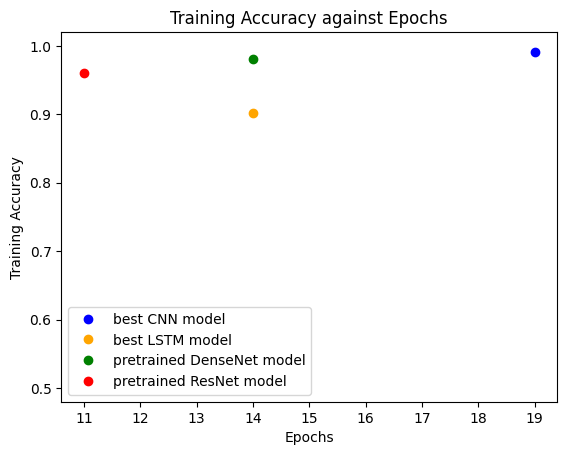

In [ ]:
x_axis1 = [num_epochs_CNN, num_epochs_LSTM, num_epochs_DenseNet, num_epochs_ResNet]
y_axis1 = [train_accuracy_CNN, train_accuracy_LSTM, train_accuracy_pretrained_DenseNet, train_accuracy_pretrained_ResNet]
colors = ['blue', 'orange', 'green', 'red']
labels = ['best CNN model', 'best LSTM model', 'pretrained DenseNet model', 'pretrained ResNet model']

for i in range(len(y_axis1)):
  plt.plot(x_axis1[i], y_axis1[i], 'o', color = colors[i], label = labels[i])
#plt.plot(x_axis1, y_axis1, 'o')

plt.ylim(0.48, 1.02)


plt.xlabel('Epochs')
plt.ylabel('Training Accuracy')
plt.title('Training Accuracy against Epochs')
plt.legend()
plt.show()

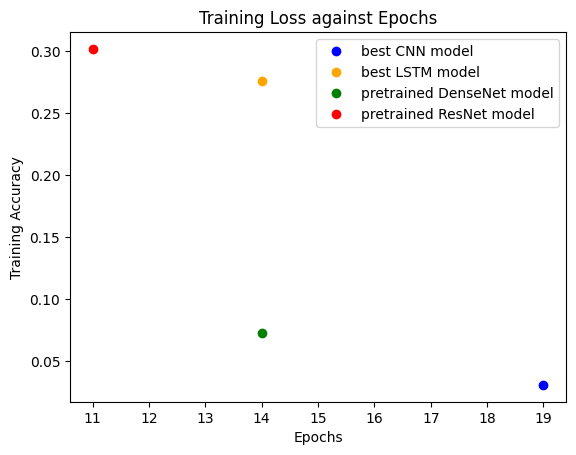

In [ ]:
y_axis2 = [train_loss_CNN, train_loss_LSTM, train_loss_pretrained_DenseNet, train_loss_pretrained_ResNet]

for i in range(len(x_axis1)):
  plt.plot(x_axis1[i], y_axis2[i], 'o', color = colors[i], label = labels[i])
#plt.plot(x_axis1, y_axis1, 'o')

#plt.ylim(0.48, 1.02)


plt.xlabel('Epochs')
plt.ylabel('Training Accuracy')
plt.title('Training Loss against Epochs')
plt.legend()
plt.show()

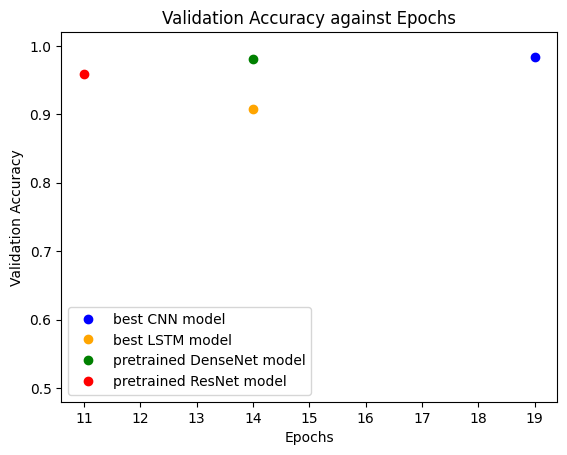

In [ ]:
y_axis3 = [validation_accuracy_CNN, validation_accuracy_LSTM, validation_accuracy_pretrained_DenseNet, validation_accuracy_pretrained_ResNet]

for i in range(len(y_axis1)):
  plt.plot(x_axis1[i], y_axis3[i], 'o', color = colors[i], label = labels[i])

plt.ylim(0.48, 1.02)

plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy against Epochs')
plt.legend()
plt.show()

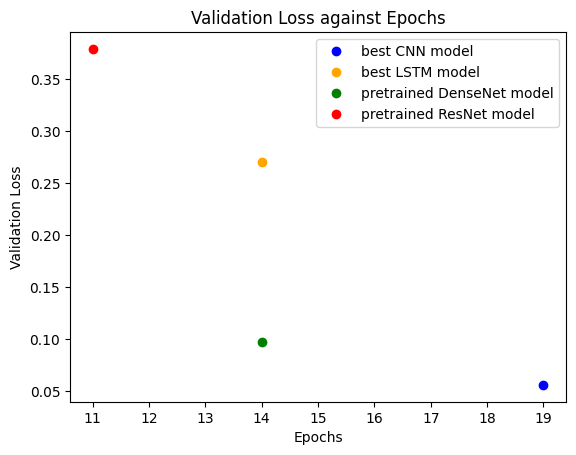

In [ ]:
y_axis4 = [validation_loss_CNN, validation_loss_LSTM, validation_loss_pretrained_DenseNet, validation_loss_pretrained_ResNet]
for i in range(len(y_axis1)):
  plt.plot(x_axis1[i], y_axis4[i], 'o', color = colors[i], label = labels[i])
#plt.plot(x_axis1, y_axis1, 'o')

#plt.ylim(0.48, 1.02)


plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.title('Validation Loss against Epochs')
plt.legend()
plt.show()

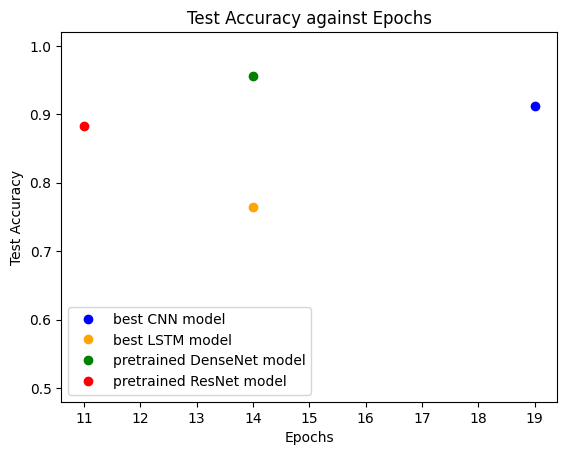

In [ ]:
y_axis5 = [test_accuracy_CNN, test_accuracy_LSTM, test_accuracy_pretrained_DenseNet, test_accuracy_pretrained_ResNet]

for i in range(len(y_axis1)):
  plt.plot(x_axis1[i], y_axis5[i], 'o', color = colors[i], label = labels[i])

plt.ylim(0.48, 1.02)


plt.xlabel('Epochs')
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy against Epochs')
plt.legend()
plt.show()

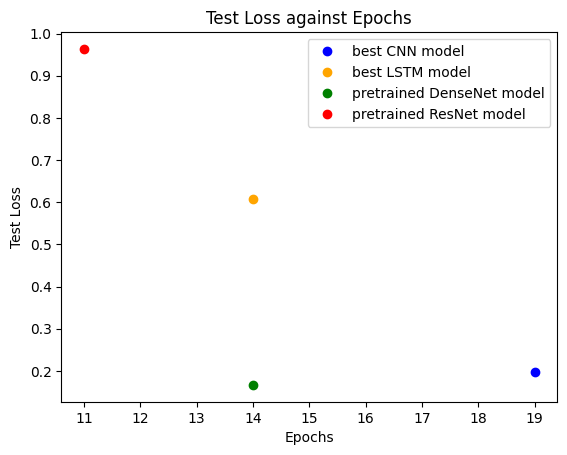

In [ ]:
y_axis6 = [test_loss_CNN, test_loss_LSTM, test_loss_pretrained_DenseNet, test_loss_pretrained_ResNet]

for i in range(len(y_axis1)):
  plt.plot(x_axis1[i], y_axis6[i], 'o', color = colors[i], label = labels[i])
#plt.plot(x_axis1, y_axis


plt.xlabel('Epochs')
plt.ylabel('Test Loss')
plt.title('Test Loss against Epochs')
plt.legend()
plt.show()

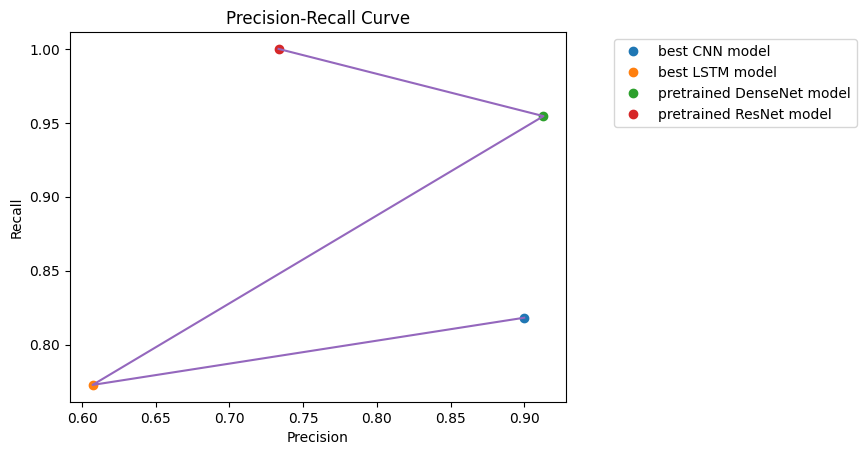

In [ ]:
precision_values = [precision_CNN, precision_LSTM, precision_DenseNet, precision_ResNet]
recall_values = [recall_CNN, recall_LSTM, recall_DenseNet, recall_ResNet]

for i in range(len(precision_values)):
  plt.plot(precision_values[i], recall_values[i], 'o', label = labels[i])

plt.plot(precision_values, recall_values)


plt.xlabel('Precision')
plt.ylabel('Recall')
plt.title('Precision-Recall Curve')
plt.legend(bbox_to_anchor=(1.6, 1), loc = 'upper right')
plt.show()



In [ ]:
validation_accuracy_base_paper = 0.846

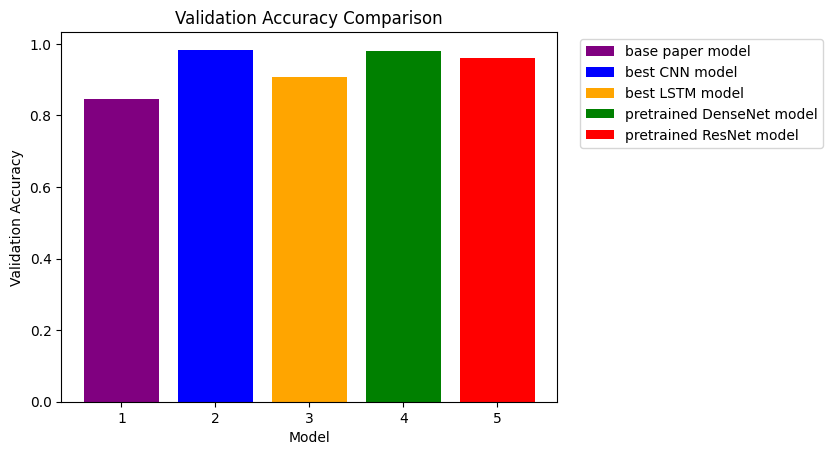

In [ ]:
all_validation_accuracies = [validation_accuracy_base_paper, validation_accuracy_CNN, validation_accuracy_LSTM, validation_accuracy_pretrained_DenseNet, validation_accuracy_pretrained_ResNet]
x_axis_bar = [1, 2, 3, 4, 5]

for i in range(len(all_validation_accuracies)):
  if i == 0:
    plt.bar(x_axis_bar[i], all_validation_accuracies[i], label = 'base paper model', color = 'purple')
  else:
    plt.bar(x_axis_bar[i], all_validation_accuracies[i], label = labels[i-1], color = colors[i-1])

plt.legend(bbox_to_anchor=(1.55, 1), loc = 'upper right')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Validation Accuracy')
plt.show()

In [ ]:
test_accuracy_base_paper = 0.86

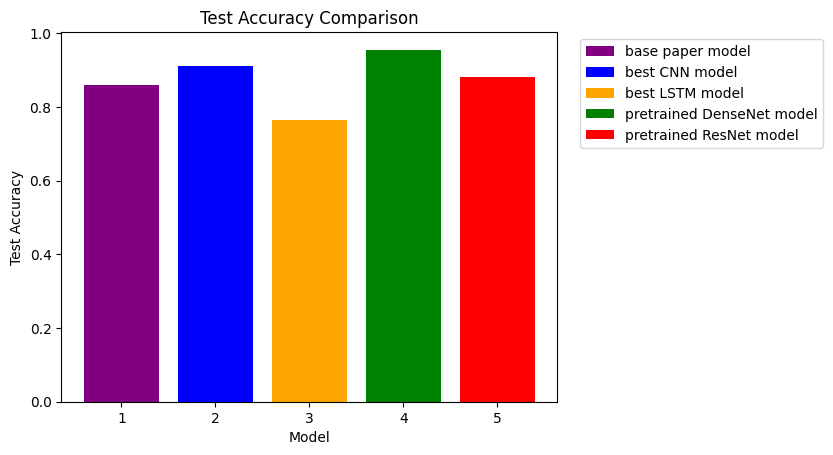

In [ ]:
all_test_accuracies = [test_accuracy_base_paper, test_accuracy_CNN, test_accuracy_LSTM, test_accuracy_pretrained_DenseNet, test_accuracy_pretrained_ResNet]
x_axis_bar = [1, 2, 3, 4, 5]

for i in range(len(all_test_accuracies)):
  if i == 0:
    plt.bar(x_axis_bar[i], all_test_accuracies[i], label = 'base paper model', color = 'purple')
  else:
    plt.bar(x_axis_bar[i], all_test_accuracies[i], label = labels[i-1], color = colors[i-1])

plt.legend(bbox_to_anchor=(1.55, 1), loc = 'upper right')
plt.title('Test Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Test Accuracy')
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
test_labels_predicted_CNN = model_CNN.predict(test_images)
test_labels_predicted_LSTM = model_LSTM.predict(test_images)
test_labels_predicted_pretrained_DenseNet = model_pretrained_DenseNet.predict(test_images_DenseNet)
test_labels_predicted_pretrained_ResNet = model_pretrained_ResNet.predict(test_images_DenseNet)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


In [ ]:
cm = confusion_matrix(np.argmax(test_labels, axis=1), np.argmax(test_labels_predicted_CNN, axis=1))
cm

array([[44,  2],
       [ 4, 18]])

In [ ]:
x = [0, 1]

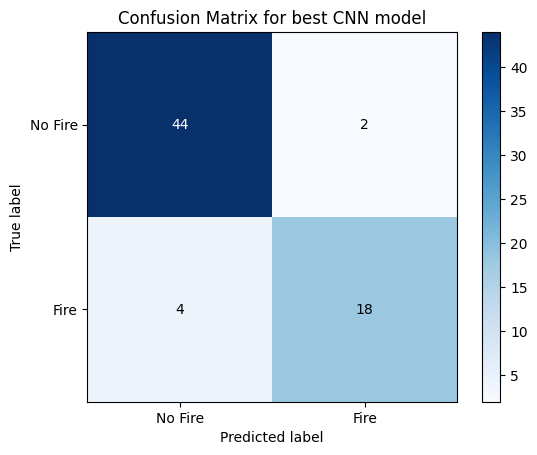

In [ ]:
cm = confusion_matrix(np.argmax(test_labels, axis=1), np.argmax(test_labels_predicted_CNN, axis=1))

fig, ax = plt.subplots()
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)  # Display the confusion matrix

# Set labels and ticks - Corrected to match 2 classes
ax.set(xticks=np.arange(cm.shape[1]),
       yticks=np.arange(cm.shape[0]),
       xticklabels=['No Fire', 'Fire'],  # Labels for 2 classes
       yticklabels=['No Fire', 'Fire'],  # Labels for 2 classes
       title='Confusion Matrix for best CNN model',
       ylabel='True label',
       xlabel='Predicted label')

ax.figure.colorbar(im, ax=ax) # Add colorbar for reference

# Loop over data dimensions and create text annotations.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2. else "black")

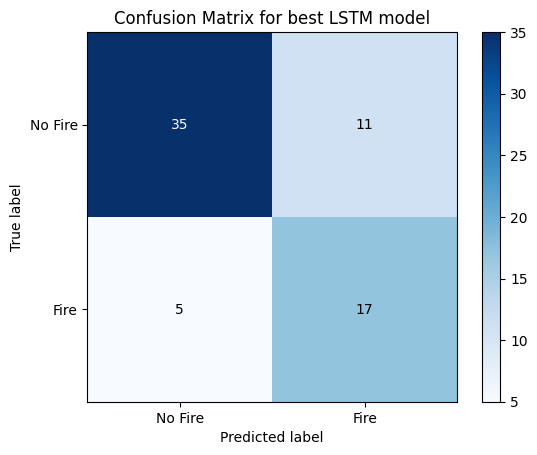

In [ ]:
cm = confusion_matrix(np.argmax(test_labels, axis=1), np.argmax(test_labels_predicted_LSTM, axis=1))

fig, ax = plt.subplots()
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)  # Display the confusion matrix

# Set labels and ticks - Corrected to match 2 classes
ax.set(xticks=np.arange(cm.shape[1]),
       yticks=np.arange(cm.shape[0]),
       xticklabels=['No Fire', 'Fire'],  # Labels for 2 classes
       yticklabels=['No Fire', 'Fire'],  # Labels for 2 classes
       title='Confusion Matrix for best LSTM model',
       ylabel='True label',
       xlabel='Predicted label')

ax.figure.colorbar(im, ax=ax) # Add colorbar for reference

# Loop over data dimensions and create text annotations.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2. else "black")

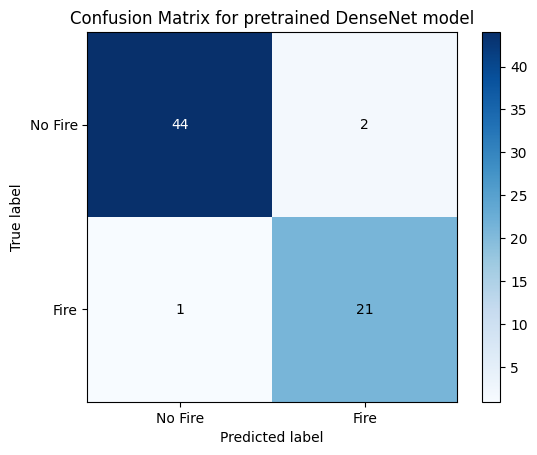

In [ ]:
cm = confusion_matrix(np.argmax(test_labels, axis=1), np.argmax(test_labels_predicted_pretrained_DenseNet, axis=1))

fig, ax = plt.subplots()
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)  # Display the confusion matrix

# Set labels and ticks - Corrected to match 2 classes
ax.set(xticks=np.arange(cm.shape[1]),
       yticks=np.arange(cm.shape[0]),
       xticklabels=['No Fire', 'Fire'],  # Labels for 2 classes
       yticklabels=['No Fire', 'Fire'],  # Labels for 2 classes
       title='Confusion Matrix for pretrained DenseNet model',
       ylabel='True label',
       xlabel='Predicted label')

ax.figure.colorbar(im, ax=ax) # Add colorbar for reference

# Loop over data dimensions and create text annotations.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2. else "black")

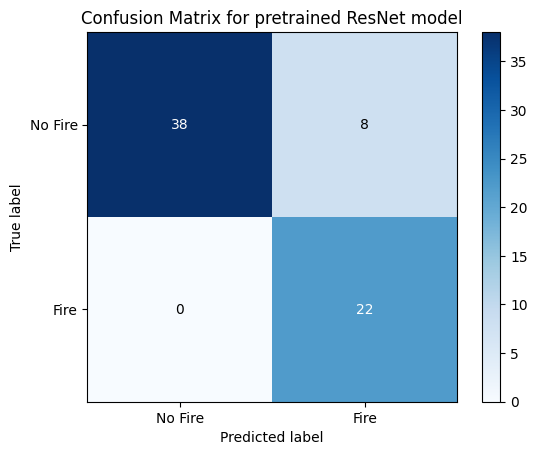

In [ ]:
cm = confusion_matrix(np.argmax(test_labels, axis=1), np.argmax(test_labels_predicted_pretrained_ResNet, axis=1))

fig, ax = plt.subplots()
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)  # Display the confusion matrix

# Set labels and ticks - Corrected to match 2 classes
ax.set(xticks=np.arange(cm.shape[1]),
       yticks=np.arange(cm.shape[0]),
       xticklabels=['No Fire', 'Fire'],  # Labels for 2 classes
       yticklabels=['No Fire', 'Fire'],  # Labels for 2 classes
       title='Confusion Matrix for pretrained ResNet model',
       ylabel='True label',
       xlabel='Predicted label')

ax.figure.colorbar(im, ax=ax) # Add colorbar for reference

# Loop over data dimensions and create text annotations.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2. else "black")

<function matplotlib.pyplot.show(close=None, block=None)>

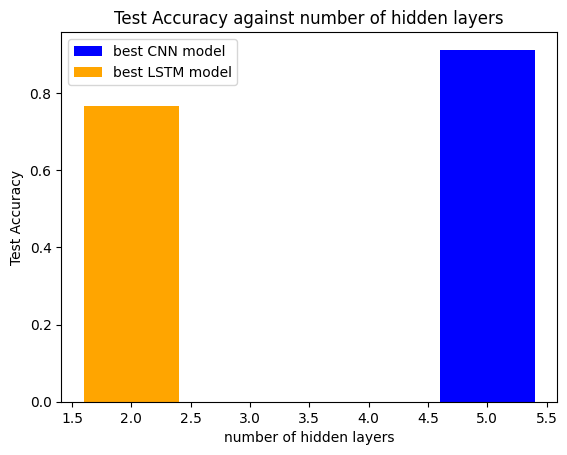

In [ ]:
plt.bar(5, test_accuracy_CNN, color = 'blue', label = 'best CNN model')
plt.bar(2, test_accuracy_LSTM, color = 'orange', label = 'best LSTM model')
plt.title('Test Accuracy against number of hidden layers')
plt.xlabel('number of hidden layers')
plt.ylabel('Test Accuracy')
plt.legend()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

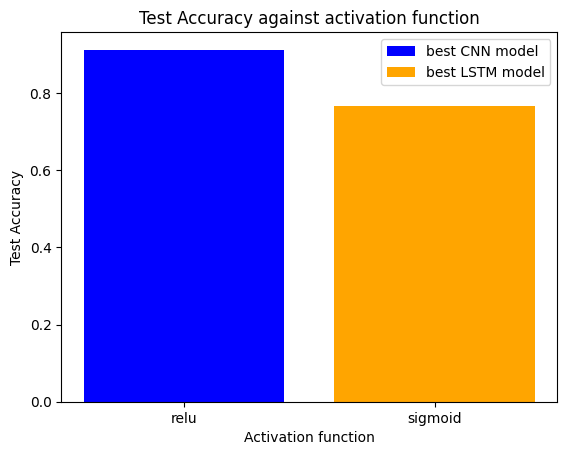

In [ ]:
plt.bar('relu', test_accuracy_CNN, color = 'blue', label = 'best CNN model')
plt.bar('sigmoid', test_accuracy_LSTM, color = 'orange', label = 'best LSTM model')
plt.title('Test Accuracy against activation function')
plt.xlabel('Activation function')
plt.ylabel('Test Accuracy')
plt.legend()
plt.show